We experiment here with a naive dataset and the FlowNet architecture.

# Generate OF data
First, we will generate a dataset of moving patterns on a image.

Then, we will use various datasets configurations in order to train a mini FlowNet inspired architecture. 

Bellow, you find some generic code for : 
* generate random patterns
* overlay a patch on a given image by generating a new one
* generate two frames corresponding to various motions

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import sklearn.model_selection as skms
import tensorflow as tf
from tensorflow.keras import layers, models

#pattern generation and overlay
def generate_pattern(w):
    return (np.random.rand(w,w,3)*255).astype(np.uint8)

def overlay_patch(img,patch,x,y):
    _img=img.copy()
    x0=max(0,x)
    y0=max(0,y)
    x1=min(x+patch.shape[0],img.shape[0])
    y1=min(y+patch.shape[1],img.shape[1])
    x2=x1-x
    y2=y1-y
    _img[x0:x1,y0:y1]=patch[(x0-x):x2,(y0-y):y2]
    return _img,(x0,y0,x1,y1)

#generate OF ground truth motion
def generate_motions(img,p,_min,_max,times):
    motions=[]
    for i in range(times):
        ok=False
        while not ok:
            x=int(np.random.randint(img.shape[0]-p.shape[0]/2))
            y=int(np.random.randint(img.shape[1]-p.shape[1]/2))
            xdx=int(np.random.randint(img.shape[0]-p.shape[0]/2))
            ydy=int(np.random.randint(img.shape[1]-p.shape[1]/2))
            ok=abs(xdx-x)<=_max and abs(xdx-x)>=_min and abs(ydy-y)<=_max and abs(ydy-y)>=_min
        
        _img1,(x0,y0,x1,y1)=overlay_patch(img,p,x,y)
        _img2,_=overlay_patch(img,p,xdx,ydy)
        
        _of=np.zeros((_img1.shape[0],_img1.shape[1],2))
        _of[x0:x1,y0:y1]=np.array([xdx-x,ydy-y])
        motions.append([cv2.cvtColor(_img1,cv2.COLOR_RGB2GRAY),cv2.cvtColor(_img2,cv2.COLOR_RGB2GRAY),_of])
    return motions

#visualisation
def layout_images(images, n_rows=None, n_cols=None, border_size=2):
    height, width, n_channels = images[0].shape
    height, width = height + border_size, width + border_size
    if n_cols is None or n_rows is None:
        n_cols = int(np.sqrt(len(images)))
        if n_cols**2 < len(images):
            n_cols += 1
        n_rows = n_cols
    output_img = np.ones((n_rows*height+border_size, n_cols*width+border_size, n_channels), dtype=images[0].dtype)*255
    for i, p in enumerate(images):
        r, c = i//n_cols, i%n_cols
        output_img[border_size+r*height:(r+1)*height, border_size+c*width:(c+1)*width] = p
    return output_img

def optical_flow_to_rgb(flow):
    # The representation relies on the HSV color space, where colors are represented by their hue (as an angle),
    # their saturation and their intensity (value)
    flow_hsv = np.zeros(flow.shape[:2] + (3,), dtype=np.float32)
    # The hue (H) is the orientation of optical flow vectors
    flow_hsv[...,0] = np.arctan2(flow[...,1], flow[...,0])/np.pi*180. + 180.
    # Saturation (S) is just a dummy dimension here
    flow_hsv[...,1] = 1.
    # Intensity (V) is used for the norm (amplitude) of flow vectors, normalized in [0,1]
    flow_hsv[...,2] = np.linalg.norm(flow, axis=2, ord=2) # norms (amplitudes) of vectors
    flow_hsv[...,2] = (flow_hsv[...,2] - np.min(flow_hsv[...,2])) / (np.max(flow_hsv[...,2]) - np.min(flow_hsv[...,2]))
    # The final image is converted back to RGB for display
    return cv2.cvtColor(flow_hsv, cv2.COLOR_HSV2RGB)

def show_motions_and_of(motions):
    ofs=[]
    for i in range(len(motions)):
        img1=motions[i][0]
        img2=motions[i][1]
        img_of=(optical_flow_to_rgb(motions[i][2])*255).astype(np.uint8)
        ofs.append(layout_images([cv2.cvtColor(img1,cv2.COLOR_GRAY2BGR),cv2.cvtColor(img2,cv2.COLOR_GRAY2BGR),img_of],1,3,2))
    plt.imshow(layout_images(ofs))
        

2026-01-11 23:05:18.499275: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2026-01-11 23:05:19.387932: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
2026-01-11 23:05:23.990946: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


Write a code to generate a dataset that contains 100 OF where 10 differents patterns of a size (10,10) generate 100 differents motions of low intensities ranging from 1 to 3 over a dark image of size (32,32).

Sample 10 motions for all the motions that where generated and use the function "show_motions_and_of" in order to visualize them.

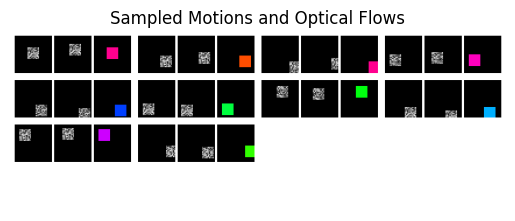

In [2]:
nb_patterns = 10
nb_motions = 10 # number of motions per pattern: total motions = nb_patterns * nb_motions
img_size = 32
pattern_size = 10
motion_min = 1
motion_max = 3

all_motions = []
dark_img = np.zeros((img_size, img_size, 3), dtype=np.uint8)

for i in range(nb_patterns):
    p = generate_pattern(pattern_size)
    motions = generate_motions(dark_img, p, motion_min, motion_max, nb_motions)
    all_motions += motions

# Sample 10 motions for visualization
sample_indices = np.random.choice(len(all_motions), 10, replace=False)
sampled_motions = [all_motions[idx] for idx in sample_indices]
show_motions_and_of(sampled_motions)
plt.title('Sampled Motions and Optical Flows')
plt.axis('off')
plt.show()

In [3]:
print(f"Nombre total de motions: {len(all_motions)}")
print(f"Taille de l'image: {img_size}x{img_size}")
print(f"Taille des patterns: {pattern_size}x{pattern_size}")


Nombre total de motions: 100
Taille de l'image: 32x32
Taille des patterns: 10x10


In [4]:
all_displacements = [
    tuple(flow[i, j])
    for motion in all_motions
    for flow in [motion[2]]
    for i in range(flow.shape[0])
    for j in range(flow.shape[1])
    if not np.all(flow[i, j] == 0)
]

if all_displacements:
    dx_vals = [d[0] for d in all_displacements]
    dy_vals = [d[1] for d in all_displacements]
    print(f"displacement X - Min: {min(dx_vals)}, Max: {max(dx_vals)}")
    print(f"displacement Y - Min: {min(dy_vals)}, Max: {max(dy_vals)}")
    print(f"unique values X: {set(dx_vals)}")
    print(f"unique values Y: {set(dy_vals)}")

displacement X - Min: -3.0, Max: 3.0
displacement Y - Min: -3.0, Max: 3.0
unique values X: {np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(-1.0), np.float64(-3.0), np.float64(-2.0)}
unique values Y: {np.float64(1.0), np.float64(2.0), np.float64(3.0), np.float64(-1.0), np.float64(-3.0), np.float64(-2.0)}


# Network and training

Create a network that has the structure of an autoencoder with 1 convolutional layer followed by 1 (de)convolutional or convolutional transpose layers.

The input corresponds to a 2 channel matrix where the first channel corresponds to the first image and the second channel corresponds to the second image.

The ouput corresponds to the 2 channel matrix corresponding to the expected optical flow.

MSELoss can be used for tranining.

First, construct the X and y from the all_motions list and create a train/test configuration (using sklearn.model_selection.train_test_split)

In [5]:
# Prepare the dataset
X = np.zeros((len(all_motions), all_motions[0][0].shape[0], all_motions[0][0].shape[1], 2))
y = np.zeros((len(all_motions), all_motions[0][0].shape[0], all_motions[0][0].shape[1], 2))

for i in range(len(all_motions)):
    # Input: two consecutive frames as two channels
    X[i, :, :, 0] = all_motions[i][0]  # First frame
    X[i, :, :, 1] = all_motions[i][1]  # Second frame
    y[i] = all_motions[i][2]  # Optical flow (2 channels: dx, dy)

# Normalize inputs (0-255 -> 0-1) for better training
X = X.astype(np.float32) / 255.0

x_train, x_test, y_train, y_test = skms.train_test_split(X, y, test_size=0.2, random_state=42)

In [6]:
print(f"Training samples: {len(x_train)}")
print(f"Test samples: {len(x_test)}")
print(f"Input shape: {x_train[0].shape}")
print(f"Output shape: {y_train[0].shape}")

Training samples: 80
Test samples: 20
Input shape: (32, 32, 2)
Output shape: (32, 32, 2)


Create the input tensor

In [7]:
inputs = tf.keras.Input(shape=x_train[0].shape)
print(len(x_train),inputs.shape)

80 (None, 32, 32, 2)


Create the autoencoder architecture :

* encoder : 1 Conv2D layer with kernel size 3x3 + 1 maxpoling 2x2
* decoder : 1 Conv2DTranspose layer with kernel size 3x3 with stride 2 + 1 final Conv2D layer using 2 filters and a stride of one in order to reconstruct the 2 channels of the OF

For the encoder/decoder components you can start by using 64 filters and use "same" padding.

What activation function should you use for the last conv transpose layer ? ReLu would be a good fit ?

Use MSELoss

In [8]:
# Convolutional Layer
# Encoder: 1 Conv2D layer with kernel size 3x3 + 1 maxpooling 2x2
conv1 = layers.Conv2D(64, (3, 3), padding='same', activation='relu')(inputs)
# Pooling Layer #1
pool1 = layers.MaxPooling2D(pool_size=(2, 2), strides=2)(conv1)

# Convolutional Transpose Layer
# Decoder: 1 Conv2DTranspose layer with kernel size 3x3 with stride 2
deconv1 = layers.Conv2DTranspose(64, (3, 3), strides=2, padding='same', activation='relu')(pool1)

# Convolutional Layer
# Final Conv2D layer to reconstruct the 2 channels of OF
OF = layers.Conv2D(2, (3, 3), padding='same', activation='linear')(deconv1)

model = tf.keras.Model(inputs=inputs, outputs=OF)

mseloss=tf.keras.losses.MeanSquaredError()

model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss=[mseloss], metrics=['accuracy'])

model.summary()



Model: "functional"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 32, 32, 2)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 32, 32, 64)     │         1,216 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 16, 16, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 32, 32, 64)     │        36,928 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 32, 32, 2)      │         1,154 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 39,298 (153.51 KB)

 Trainable params: 39,298 (153.51 KB)

 Non-trainable params: 0 (0.00 B)

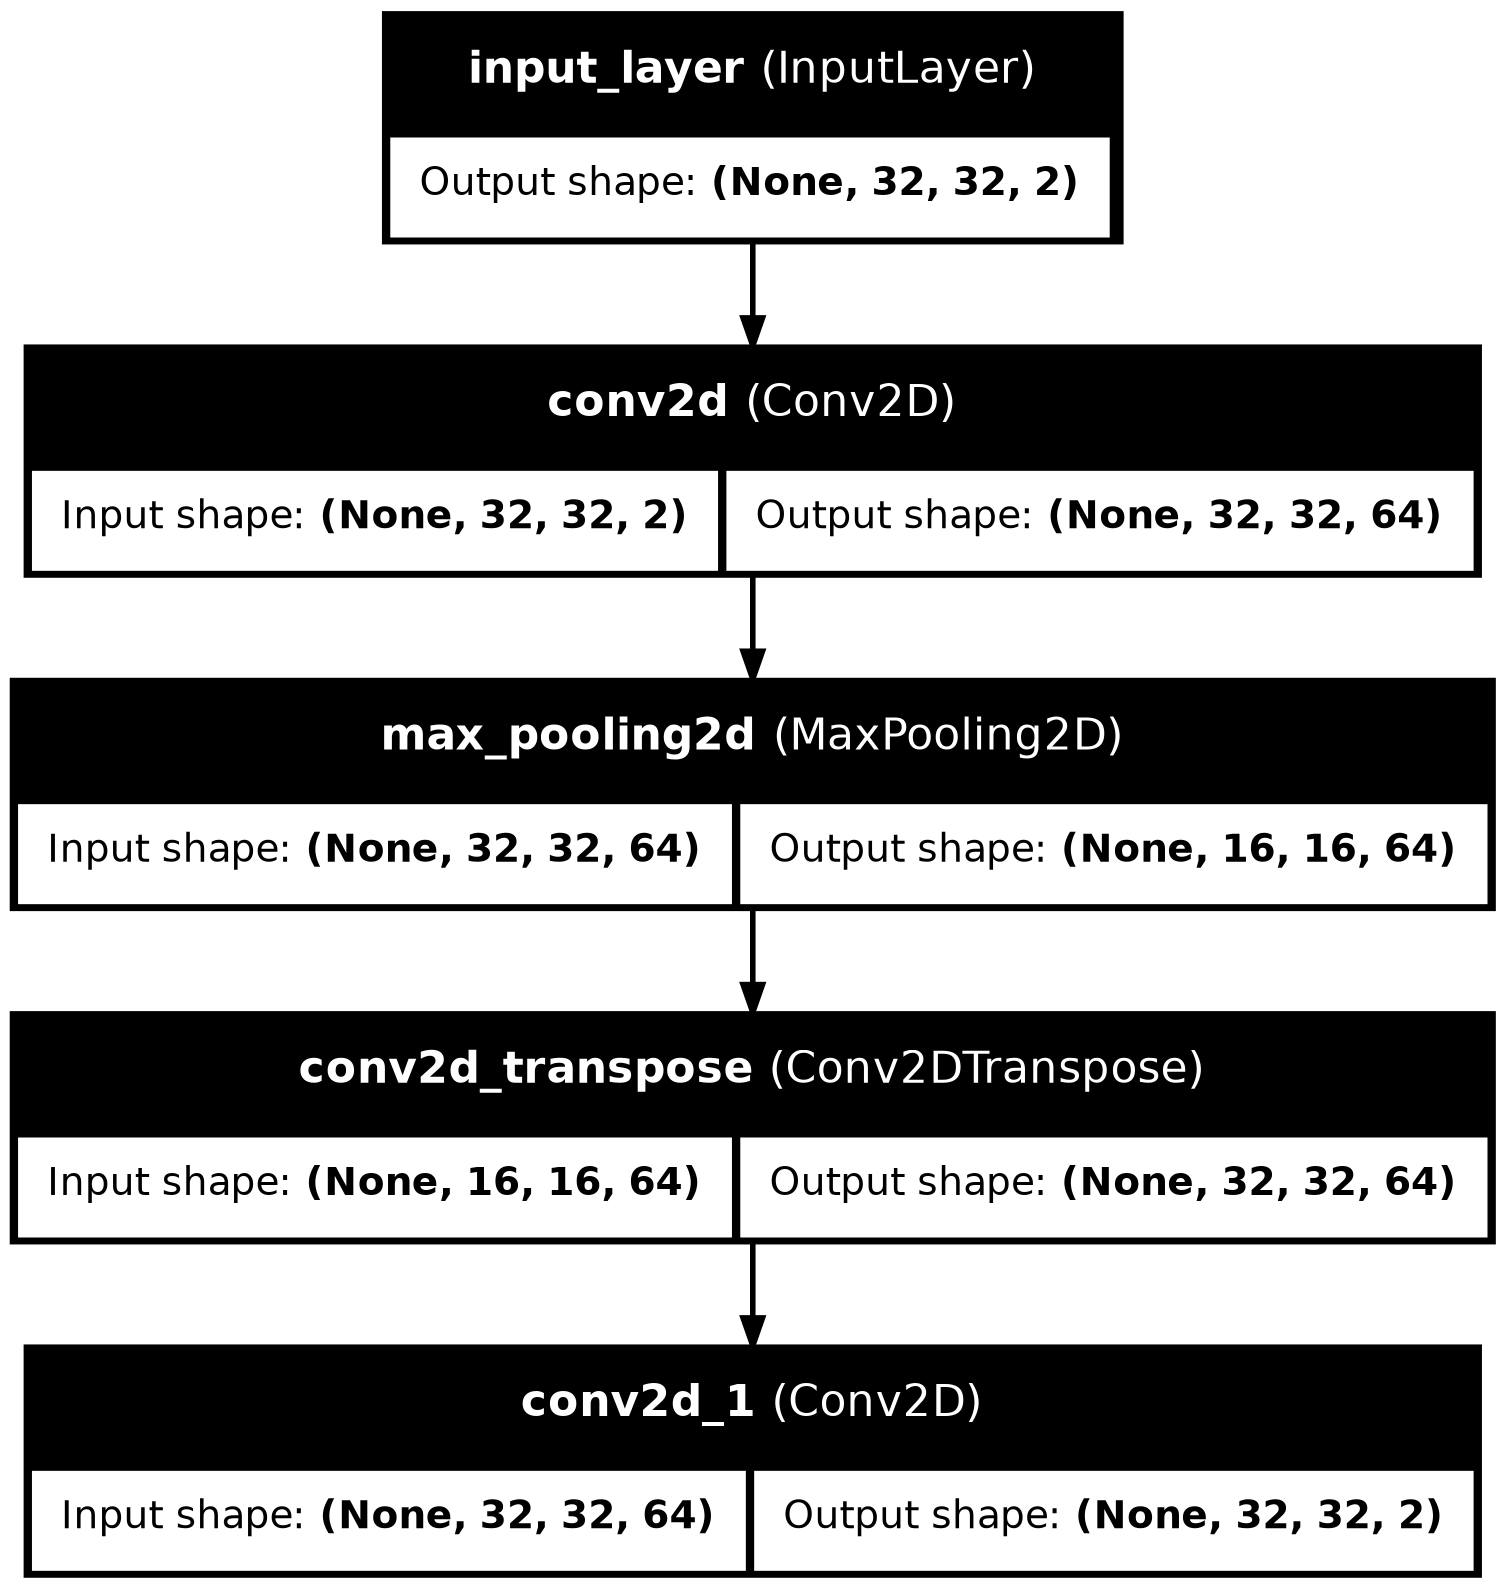

In [9]:
tf.keras.utils.plot_model(model, show_shapes=True, show_layer_names=True)

You can use the following callback for visualizing at the end of each 5 epochs the evolution in terms of OF computation

In [10]:
train_samples=np.random.choice(range(y_train.shape[0]),6)
y_pred_train=model.predict(x_train[train_samples])
size=x_train[0].shape[0]

class CustomCallback(tf.keras.callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        if epoch%5!=0:
            return
        res_imgs=[]
        y_pred_train=model.predict(x_train[train_samples])
        for i,s in enumerate(train_samples):
          _img1=x_train[s][:,:,0].reshape(size,size,1).astype(np.uint8)
          _img2=x_train[s][:,:,1].reshape(size,size,1).astype(np.uint8)
          img1=cv2.cvtColor(_img1,cv2.COLOR_GRAY2BGR)
          img2=cv2.cvtColor(_img2,cv2.COLOR_GRAY2BGR)
          of_ok=(optical_flow_to_rgb(y_train[s])*255).astype(np.uint8)
          of_pred=(optical_flow_to_rgb(y_pred_train[i])*255).astype(np.uint8)
          res_imgs.append(layout_images([img1,img2,of_ok,of_pred],1,4))
        plt.imshow(layout_images(res_imgs))
        plt.pause(0.1)

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step


Fit the model using 40 epochs and a batch size of 16

Epoch 1/40
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step - accuracy: 0.5435 - loss: 0.388


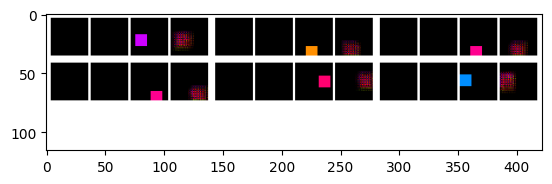

5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 97ms/step - accuracy: 0.2277 - loss: 0.4406
Epoch 2/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.3784 - loss: 0.4401
Epoch 3/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.4934 - loss: 0.4396
Epoch 4/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.4266 - loss: 0.4391
Epoch 5/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.6136 - loss: 0.4386
Epoch 6/40
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.8558 - loss: 0.351


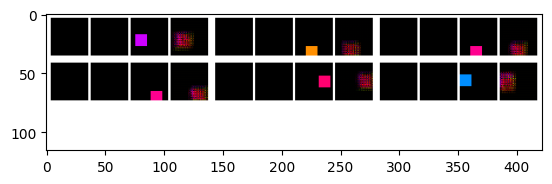

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 80ms/step - accuracy: 0.6147 - loss: 0.4381
Epoch 7/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.7160 - loss: 0.4376
Epoch 8/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8210 - loss: 0.4371
Epoch 9/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8258 - loss: 0.4367
Epoch 10/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8282 - loss: 0.4362
Epoch 11/40
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.8302 - loss: 0.436


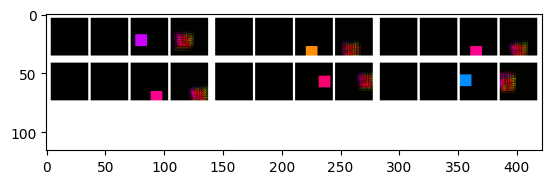

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.8281 - loss: 0.4356
Epoch 12/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8291 - loss: 0.4350
Epoch 13/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8326 - loss: 0.4345
Epoch 14/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8376 - loss: 0.4338
Epoch 15/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8411 - loss: 0.4331
Epoch 16/40
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step - accuracy: 0.8391 - loss: 0.458


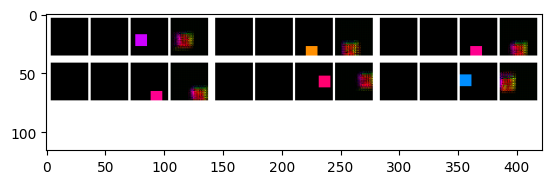

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.8457 - loss: 0.4325
Epoch 17/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8508 - loss: 0.4318
Epoch 18/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8538 - loss: 0.4311
Epoch 19/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8591 - loss: 0.4302
Epoch 20/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8638 - loss: 0.4294
Epoch 21/40
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step - accuracy: 0.8672 - loss: 0.356


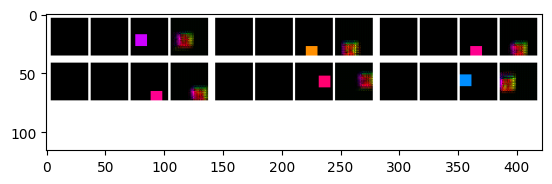

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step - accuracy: 0.8666 - loss: 0.4285
Epoch 22/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8680 - loss: 0.4276
Epoch 23/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8729 - loss: 0.4267
Epoch 24/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - accuracy: 0.8742 - loss: 0.4256
Epoch 25/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8717 - loss: 0.4245
Epoch 26/40
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 47ms/step - accuracy: 0.8770 - loss: 0.367


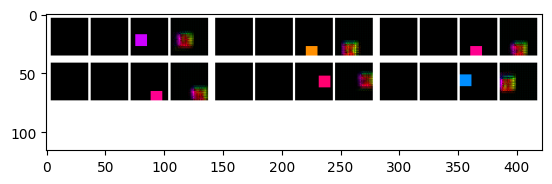

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 91ms/step - accuracy: 0.8719 - loss: 0.4233
Epoch 27/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step - accuracy: 0.8755 - loss: 0.4221
Epoch 28/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - accuracy: 0.8798 - loss: 0.4209
Epoch 29/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8805 - loss: 0.4196
Epoch 30/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 17ms/step - accuracy: 0.8716 - loss: 0.4184
Epoch 31/40
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step - accuracy: 0.8832 - loss: 0.418


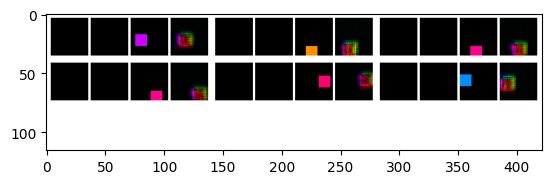

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step - accuracy: 0.8839 - loss: 0.4168
Epoch 32/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - accuracy: 0.8915 - loss: 0.4158
Epoch 33/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8928 - loss: 0.4141
Epoch 34/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8766 - loss: 0.4127
Epoch 35/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8741 - loss: 0.4111
Epoch 36/40
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step - accuracy: 0.8884 - loss: 0.343


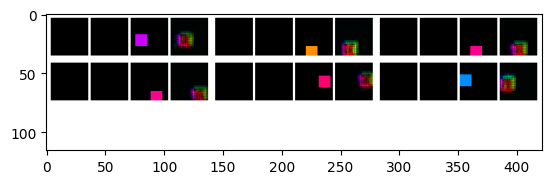

5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.8738 - loss: 0.4096
Epoch 37/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step - accuracy: 0.8787 - loss: 0.4080
Epoch 38/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 18ms/step - accuracy: 0.8822 - loss: 0.4066
Epoch 39/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - accuracy: 0.8858 - loss: 0.4049
Epoch 40/40
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - accuracy: 0.8849 - loss: 0.4032


In [11]:
nb_epochs=40

x_train_arr=np.array(x_train).reshape(len(x_train),x_train[0].shape[0],x_train[0].shape[1],x_train[0].shape[2])
y_train_arr=np.array(y_train).reshape(len(y_train),y_train[0].shape[0],y_train[0].shape[1],y_train[0].shape[2])
history = model.fit(x=x_train_arr, y=y_train_arr, batch_size=16, epochs=nb_epochs,verbose=True,callbacks=[CustomCallback()])

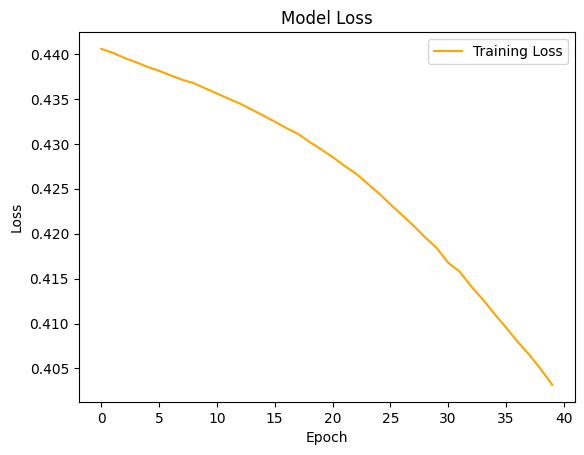

In [12]:
lplt = plt.subplot(1, 1, 1)
lplt.plot(history.history['loss'], label='Training Loss', color='orange')
lplt.set_title('Model Loss')
lplt.set_xlabel('Epoch')
lplt.set_ylabel('Loss')
lplt.legend()
plt.show()

Test 1/Compute the endpoint error metrics for the train (x_train) and test (x_test) data.

**Endpoint Error (EE) formula:**
$$
EE = \sqrt{(u_{pred} - u_{gt})^2 + (v_{pred} - v_{gt})^2}
$$

Where:
- $ u_{pred}, v_{pred} $ are the predicted optical flow components
- $ u_{gt}, v_{gt} $ are the ground truth optical flow components

In [13]:
def compute_endpoint_error(y_true, y_pred):
    u_diff = y_pred[..., 0] - y_true[..., 0]
    v_diff = y_pred[..., 1] - y_true[..., 1]
    
    # Compute Euclidean distance (Endpoint Error)
    ee = np.sqrt(u_diff**2 + v_diff**2)
    
    mean_ee = np.mean(ee)
    std_ee = np.std(ee)
    median_ee = np.median(ee)
    
    # Only consider pixels with actual motion (non-zero ground truth)
    # Calculate mask for non-zero ground truth flow
    gt_magnitude = np.sqrt(y_true[..., 0]**2 + y_true[..., 1]**2)
    non_zero_mask = gt_magnitude > 0
    
    if np.any(non_zero_mask):
        mean_ee_non_zero = np.mean(ee[non_zero_mask])
        std_ee_non_zero = np.std(ee[non_zero_mask])
        median_ee_non_zero = np.median(ee[non_zero_mask])
    else:
        mean_ee_non_zero = std_ee_non_zero = median_ee_non_zero = 0
    
    return {
        'ee_map': ee,  # Endpoint error per pixel
        'mean_ee': mean_ee,
        'std_ee': std_ee,
        'median_ee': median_ee,
        'mean_ee_non_zero': mean_ee_non_zero,
        'std_ee_non_zero': std_ee_non_zero,
        'median_ee_non_zero': median_ee_non_zero,
        'non_zero_pixels': np.sum(non_zero_mask)
    }


In [14]:
y_pred_train = model.predict(x_train, verbose=0)

y_pred_test = model.predict(x_test, verbose=0)

print("\n=== Training Data Endpoint Error ===")
train_ee = compute_endpoint_error(y_train, y_pred_train)
print(f"Mean EE (all pixels): {train_ee['mean_ee']:.4f}")
print(f"Std EE (all pixels): {train_ee['std_ee']:.4f}")
print(f"Median EE (all pixels): {train_ee['median_ee']:.4f}")
print(f"\nMean EE (non-zero pixels only): {train_ee['mean_ee_non_zero']:.4f}")
print(f"Std EE (non-zero pixels only): {train_ee['std_ee_non_zero']:.4f}")
print(f"Median EE (non-zero pixels only): {train_ee['median_ee_non_zero']:.4f}")
print(f"Number of non-zero pixels: {train_ee['non_zero_pixels']}")



=== Training Data Endpoint Error ===
Mean EE (all pixels): 0.2924
Std EE (all pixels): 0.8477
Median EE (all pixels): 0.0150

Mean EE (non-zero pixels only): 2.8578
Std EE (non-zero pixels only): 0.7774
Median EE (non-zero pixels only): 2.9861
Number of non-zero pixels: 7461


In [15]:
print("\n=== Test Data Endpoint Error ===")
test_ee = compute_endpoint_error(y_test, y_pred_test)
print(f"Mean EE (all pixels): {test_ee['mean_ee']:.4f}")
print(f"Std EE (all pixels): {test_ee['std_ee']:.4f}")
print(f"Median EE (all pixels): {test_ee['median_ee']:.4f}")
print(f"\nMean EE (non-zero pixels only): {test_ee['mean_ee_non_zero']:.4f}")
print(f"Std EE (non-zero pixels only): {test_ee['std_ee_non_zero']:.4f}")
print(f"Median EE (non-zero pixels only): {test_ee['median_ee_non_zero']:.4f}")
print(f"Number of non-zero pixels: {test_ee['non_zero_pixels']}")


=== Test Data Endpoint Error ===
Mean EE (all pixels): 0.3295
Std EE (all pixels): 0.9357
Median EE (all pixels): 0.0150

Mean EE (non-zero pixels only): 3.1535
Std EE (non-zero pixels only): 0.6652
Median EE (non-zero pixels only): 3.1291
Number of non-zero pixels: 1930


The Mean/Median Endpoint Error (non-zero pixels) on the test set is relatively high (2.59/2.92), indicating the model struggles to predict accurate optical flow for moving regions. Performance is not optimal and could be improved.

Test 2/ Generate some new test data (x_test2) by considering 10 new patterns. For a fair comparison generate as much test data as in x_test.shape[0]. It results that each new pattern will generate (x_test.shape[0]//10) motions.

In [16]:
# Generate new test data (x_test2) with 10 new patterns
nb_new_patterns = 10
nb_new_motions_per_pattern = x_test.shape[0] // nb_new_patterns
img_size = 32
pattern_size = 10
motion_min = 1
motion_max = 3

dark_img = np.zeros((img_size, img_size, 3), dtype=np.uint8)
new_motions = []

for i in range(nb_new_patterns):
    p = generate_pattern(pattern_size)
    motions = generate_motions(dark_img, p, motion_min, motion_max, nb_new_motions_per_pattern)
    new_motions += motions

# Prepare x_test2 and y_test2
x_test2 = np.zeros((len(new_motions), img_size, img_size, 2), dtype=np.float32)
y_test2 = np.zeros((len(new_motions), img_size, img_size, 2), dtype=np.float32)

for i, motion in enumerate(new_motions):
    x_test2[i, :, :, 0] = motion[0]
    x_test2[i, :, :, 1] = motion[1]
    y_test2[i] = motion[2]

x_test2 = x_test2 / 255.0  # Normalize

print(f"x_test2 shape: {x_test2.shape}")
print(f"y_test2 shape: {y_test2.shape}")

x_test2 shape: (20, 32, 32, 2)
y_test2 shape: (20, 32, 32, 2)


Increase the number of epochs, increase the number of training samples, number of filters, increase the autoencoder depth.

Report results.

In [17]:
# Increase number of training samples
nb_patterns = 30  # was 10
nb_motions = 20   # was 10
img_size = 32
pattern_size = 10
motion_min = 1
motion_max = 3

all_motions = []
dark_img = np.zeros((img_size, img_size, 3), dtype=np.uint8)

for i in range(nb_patterns):
    p = generate_pattern(pattern_size)
    motions = generate_motions(dark_img, p, motion_min, motion_max, nb_motions)
    all_motions += motions

# Prepare X and y
X = np.zeros((len(all_motions), img_size, img_size, 2))
y = np.zeros((len(all_motions), img_size, img_size, 2))
for i in range(len(all_motions)):
    X[i, :, :, 0] = all_motions[i][0]
    X[i, :, :, 1] = all_motions[i][1]
    y[i] = all_motions[i][2]
X = X.astype(np.float32) / 255.0

x_train, x_test, y_train, y_test = skms.train_test_split(X, y, test_size=0.2, random_state=42)

# Build deeper autoencoder with more filters
inputs = tf.keras.Input(shape=x_train[0].shape)
x = layers.Conv2D(128, (3, 3), padding='same', activation='relu')(inputs)
x = layers.MaxPooling2D(pool_size=(2, 2), strides=2)(x)
x = layers.Conv2D(256, (3, 3), padding='same', activation='relu')(x)
x = layers.MaxPooling2D(pool_size=(2, 2), strides=2)(x)
x = layers.Conv2DTranspose(256, (3, 3), strides=2, padding='same', activation='relu')(x)
x = layers.Conv2DTranspose(128, (3, 3), strides=2, padding='same', activation='relu')(x)
outputs = layers.Conv2D(2, (3, 3), padding='same', activation='linear')(x)

model = tf.keras.Model(inputs=inputs, outputs=outputs)
model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
              loss='mse', metrics=['accuracy'])
model.summary()


Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 2)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 32, 32, 128)    │         2,432 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 16, 16, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 16, 16, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 8, 8, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 16, 16, 256)    │       590,080 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 32, 32, 128)    │       295,040 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 32, 32, 2)      │         2,306 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,185,026 (4.52 MB)

 Trainable params: 1,185,026 (4.52 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 112ms/stepep - accuracy: 0.6193 - loss: 0.442


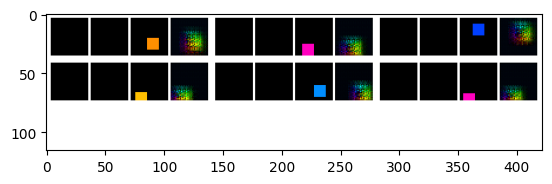

15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 128ms/step - accuracy: 0.6989 - loss: 0.4331
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 113ms/step - accuracy: 0.8440 - loss: 0.4273
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 105ms/step - accuracy: 0.6781 - loss: 0.4104
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 0.3543 - loss: 0.3676
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 98ms/step - accuracy: 0.3047 - loss: 0.3107
Epoch 6/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 64ms/stepep - accuracy: 0.3121 - loss: 0.267


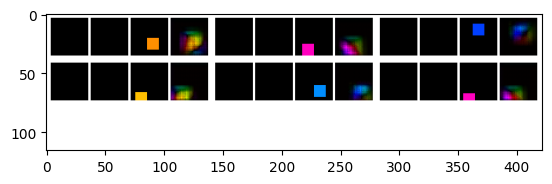

15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 118ms/step - accuracy: 0.3135 - loss: 0.2484
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 98ms/step - accuracy: 0.3260 - loss: 0.1944
Epoch 8/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 101ms/step - accuracy: 0.5935 - loss: 0.1569
Epoch 9/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 99ms/step - accuracy: 0.7606 - loss: 0.1339
Epoch 10/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 98ms/step - accuracy: 0.7569 - loss: 0.1214
Epoch 11/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/steptep - accuracy: 0.7601 - loss: 0.113


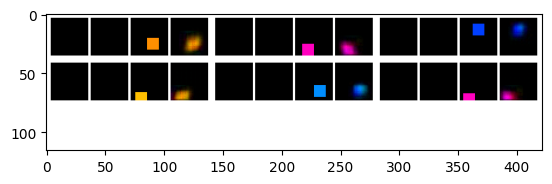

15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 186ms/step - accuracy: 0.7371 - loss: 0.1121
Epoch 12/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 95ms/step - accuracy: 0.6844 - loss: 0.1046
Epoch 13/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 0.6627 - loss: 0.0996
Epoch 14/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - accuracy: 0.6563 - loss: 0.0947
Epoch 15/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - accuracy: 0.6684 - loss: 0.0902
Epoch 16/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 67ms/stepep - accuracy: 0.5488 - loss: 0.091


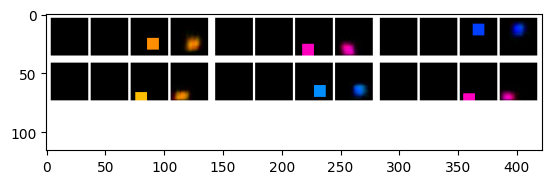

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 116ms/step - accuracy: 0.6046 - loss: 0.0872
Epoch 17/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 101ms/step - accuracy: 0.6349 - loss: 0.0841
Epoch 18/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 101ms/step - accuracy: 0.6212 - loss: 0.0813
Epoch 19/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step - accuracy: 0.5214 - loss: 0.0803
Epoch 20/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - accuracy: 0.5983 - loss: 0.0778
Epoch 21/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/stepep - accuracy: 0.4774 - loss: 0.077


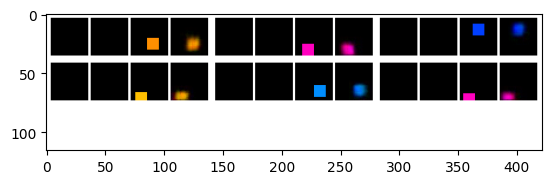

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - accuracy: 0.4824 - loss: 0.0757
Epoch 22/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.5691 - loss: 0.0736
Epoch 23/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step - accuracy: 0.5091 - loss: 0.0721
Epoch 24/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 0.4575 - loss: 0.0706
Epoch 25/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 90ms/step - accuracy: 0.5143 - loss: 0.0698
Epoch 26/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 53ms/stepep - accuracy: 0.4945 - loss: 0.067


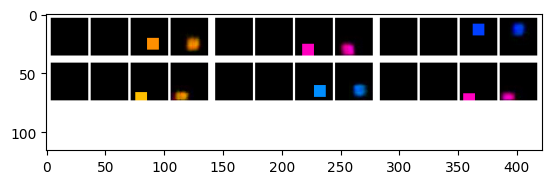

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 111ms/step - accuracy: 0.5198 - loss: 0.0682
Epoch 27/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 96ms/step - accuracy: 0.4730 - loss: 0.0669
Epoch 28/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - accuracy: 0.5035 - loss: 0.0664
Epoch 29/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 0.5143 - loss: 0.0652
Epoch 30/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.5722 - loss: 0.0634
Epoch 31/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/stepep - accuracy: 0.3890 - loss: 0.062


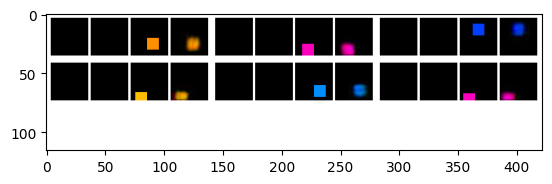

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 113ms/step - accuracy: 0.4596 - loss: 0.0621
Epoch 32/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 180ms/step - accuracy: 0.5067 - loss: 0.0611
Epoch 33/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step - accuracy: 0.5489 - loss: 0.0602
Epoch 34/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - accuracy: 0.5762 - loss: 0.0595
Epoch 35/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - accuracy: 0.4941 - loss: 0.0599
Epoch 36/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 59ms/stepep - accuracy: 0.5260 - loss: 0.058


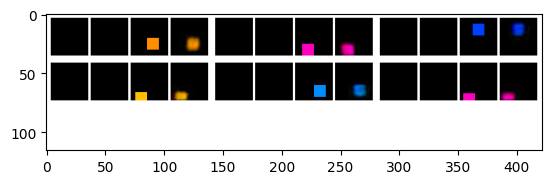

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 112ms/step - accuracy: 0.5022 - loss: 0.0588
Epoch 37/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step - accuracy: 0.5520 - loss: 0.0573
Epoch 38/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.5093 - loss: 0.0563
Epoch 39/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 99ms/step - accuracy: 0.5618 - loss: 0.0566
Epoch 40/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 98ms/step - accuracy: 0.5639 - loss: 0.0558
Epoch 41/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/stepep - accuracy: 0.5666 - loss: 0.057


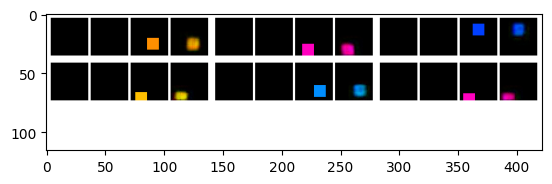

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 105ms/step - accuracy: 0.5187 - loss: 0.0554
Epoch 42/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step - accuracy: 0.4930 - loss: 0.0550
Epoch 43/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 0.5646 - loss: 0.0532
Epoch 44/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 0.4785 - loss: 0.0524
Epoch 45/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.5447 - loss: 0.0531
Epoch 46/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/stepep - accuracy: 0.5239 - loss: 0.051


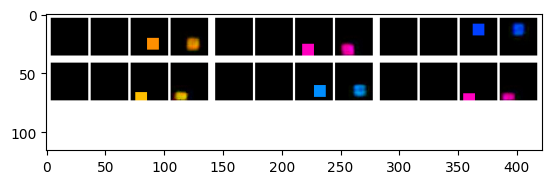

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 111ms/step - accuracy: 0.5069 - loss: 0.0518
Epoch 47/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 93ms/step - accuracy: 0.5389 - loss: 0.0507
Epoch 48/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - accuracy: 0.4787 - loss: 0.0507
Epoch 49/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.5264 - loss: 0.0498
Epoch 50/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 0.4864 - loss: 0.0490
Epoch 51/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 54ms/stepep - accuracy: 0.5531 - loss: 0.048


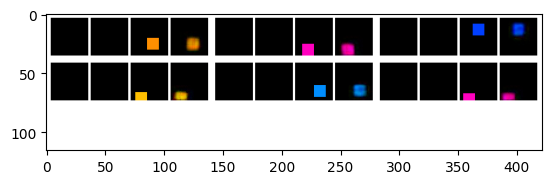

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - accuracy: 0.5487 - loss: 0.0485
Epoch 52/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step - accuracy: 0.5498 - loss: 0.0479
Epoch 53/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 174ms/step - accuracy: 0.4857 - loss: 0.0475
Epoch 54/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - accuracy: 0.5505 - loss: 0.0472
Epoch 55/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 0.5029 - loss: 0.0465
Epoch 56/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/stepep - accuracy: 0.6630 - loss: 0.047


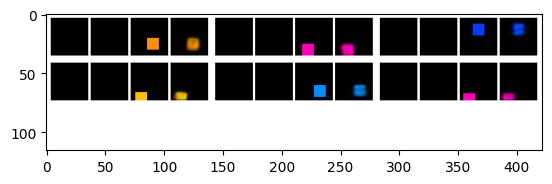

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 106ms/step - accuracy: 0.5302 - loss: 0.0464
Epoch 57/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 87ms/step - accuracy: 0.5694 - loss: 0.0460
Epoch 58/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 88ms/step - accuracy: 0.5694 - loss: 0.0461
Epoch 59/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 98ms/step - accuracy: 0.5749 - loss: 0.0459
Epoch 60/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 101ms/step - accuracy: 0.5068 - loss: 0.0450
Epoch 61/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/stepep - accuracy: 0.6380 - loss: 0.045


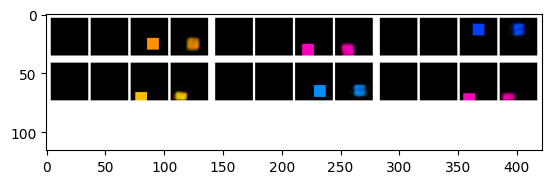

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - accuracy: 0.5168 - loss: 0.0441
Epoch 62/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 89ms/step - accuracy: 0.5957 - loss: 0.0438
Epoch 63/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 85ms/step - accuracy: 0.5427 - loss: 0.0446
Epoch 64/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - accuracy: 0.5707 - loss: 0.0452
Epoch 65/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.5811 - loss: 0.0426
Epoch 66/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/stepep - accuracy: 0.5724 - loss: 0.042


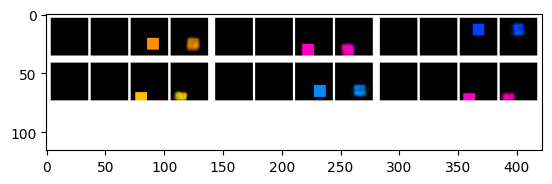

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - accuracy: 0.5270 - loss: 0.0424
Epoch 67/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.5557 - loss: 0.0418
Epoch 68/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 0.5487 - loss: 0.0411
Epoch 69/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 96ms/step - accuracy: 0.5918 - loss: 0.0409
Epoch 70/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step - accuracy: 0.5786 - loss: 0.0412
Epoch 71/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/stepep - accuracy: 0.5922 - loss: 0.039


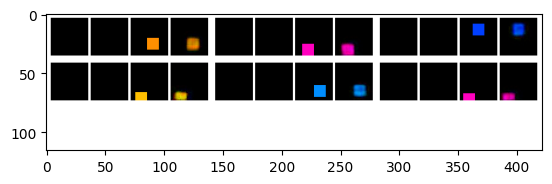

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - accuracy: 0.5402 - loss: 0.0403
Epoch 72/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 95ms/step - accuracy: 0.6343 - loss: 0.0402
Epoch 73/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 90ms/step - accuracy: 0.4855 - loss: 0.0401
Epoch 74/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 0.6231 - loss: 0.0398
Epoch 75/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 177ms/step - accuracy: 0.5181 - loss: 0.0392
Epoch 76/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 60ms/stepep - accuracy: 0.6269 - loss: 0.040


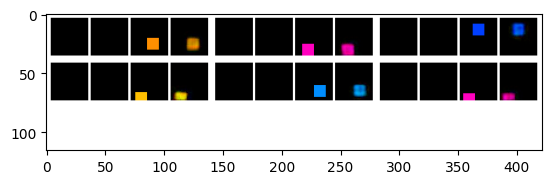

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 113ms/step - accuracy: 0.5924 - loss: 0.0387
Epoch 77/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - accuracy: 0.5780 - loss: 0.0386
Epoch 78/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.5866 - loss: 0.0389
Epoch 79/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 93ms/step - accuracy: 0.5431 - loss: 0.0379
Epoch 80/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step - accuracy: 0.5689 - loss: 0.0380
Epoch 81/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 51ms/stepep - accuracy: 0.5835 - loss: 0.036


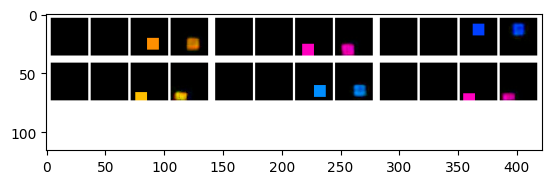

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - accuracy: 0.5695 - loss: 0.0375
Epoch 82/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 95ms/step - accuracy: 0.5412 - loss: 0.0372
Epoch 83/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 86ms/step - accuracy: 0.5635 - loss: 0.0369
Epoch 84/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 101ms/step - accuracy: 0.6118 - loss: 0.0366
Epoch 85/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - accuracy: 0.5673 - loss: 0.0371
Epoch 86/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/steptep - accuracy: 0.5557 - loss: 0.035


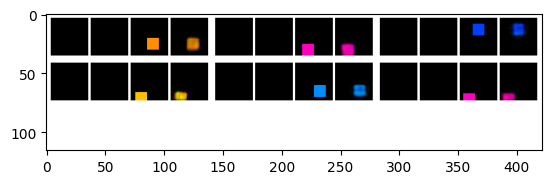

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 126ms/step - accuracy: 0.5409 - loss: 0.0361
Epoch 87/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 105ms/step - accuracy: 0.6010 - loss: 0.0355
Epoch 88/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - accuracy: 0.5194 - loss: 0.0354
Epoch 89/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - accuracy: 0.5576 - loss: 0.0349
Epoch 90/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - accuracy: 0.5970 - loss: 0.0348
Epoch 91/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/steptep - accuracy: 0.5610 - loss: 0.033


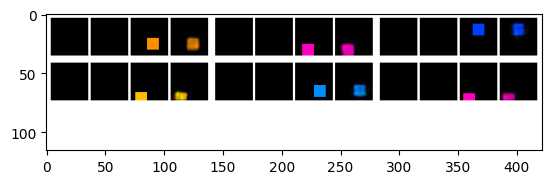

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 125ms/step - accuracy: 0.5055 - loss: 0.0343
Epoch 92/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 104ms/step - accuracy: 0.6217 - loss: 0.0340
Epoch 93/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step - accuracy: 0.5344 - loss: 0.0339
Epoch 94/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 94ms/step - accuracy: 0.5684 - loss: 0.0347
Epoch 95/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 92ms/step - accuracy: 0.5202 - loss: 0.0339
Epoch 96/100
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/stepep - accuracy: 0.6087 - loss: 0.033


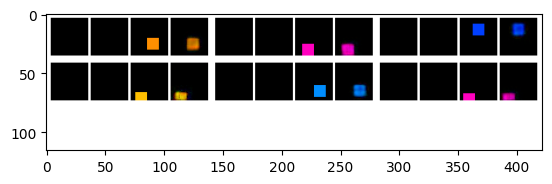

15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 115ms/step - accuracy: 0.6049 - loss: 0.0340
Epoch 97/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 95ms/step - accuracy: 0.5530 - loss: 0.0342
Epoch 98/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 91ms/step - accuracy: 0.5600 - loss: 0.0327
Epoch 99/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 1s 90ms/step - accuracy: 0.5552 - loss: 0.0326
Epoch 100/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 98ms/step - accuracy: 0.5793 - loss: 0.0320


In [18]:
nb_epochs = 100
history = model.fit(x_train, y_train, batch_size=32, epochs=nb_epochs, verbose=True, callbacks=[CustomCallback()])


In [19]:
y_pred_train = model.predict(x_train, verbose=0)
y_pred_test = model.predict(x_test, verbose=0)
train_ee = compute_endpoint_error(y_train, y_pred_train)
test_ee = compute_endpoint_error(y_test, y_pred_test)

print("\n=== Training Data Endpoint Error ===")
print(f"Mean EE (all pixels): {train_ee['mean_ee']:.4f}")
print(f"Mean EE (non-zero pixels only): {train_ee['mean_ee_non_zero']:.4f}")

print("\n=== Test Data Endpoint Error ===")
print(f"Mean EE (all pixels): {test_ee['mean_ee']:.4f}")
print(f"Mean EE (non-zero pixels only): {test_ee['mean_ee_non_zero']:.4f}")


=== Training Data Endpoint Error ===
Mean EE (all pixels): 0.0895
Mean EE (non-zero pixels only): 0.4836

=== Test Data Endpoint Error ===
Mean EE (all pixels): 0.0981
Mean EE (non-zero pixels only): 0.5384


What can you conclude?

Answer:

The updated model shows significant improvement compared to the previous version, with the mean endpoint error (EE) decreasing. This indicates that this model is much better at predicting optical flow overall.

- The low mean EE for both training and test sets (all pixels) suggests that the model fits the data well and generalizes effectively, with no signs of overfitting.
- The EE is higher when considering only non-zero (moving) pixels, which is expected because predicting motion is inherently more difficult than predicting static regions.
- The close EE values between train and test sets further confirm good generalization.

While the model performs well overall, especially for static regions, there is still room for improvement in accurately predicting optical flow in dynamic (moving) areas. Further architectural enhancements or more diverse training data may help reduce the error for moving pixels.

In [20]:
print("\n=== Evaluation on New Test Data (Unseen Patterns) ===")
y_pred_test2 = model.predict(x_test2, verbose=0)
test2_ee = compute_endpoint_error(y_test2, y_pred_test2)

print(f"Mean EE (all pixels): {test2_ee['mean_ee']:.4f}")
print(f"Mean EE (non-zero pixels only): {test2_ee['mean_ee_non_zero']:.4f}")


=== Evaluation on New Test Data (Unseen Patterns) ===
Mean EE (all pixels): 0.0984
Mean EE (non-zero pixels only): 0.5353


As we can see the model generalizes well on unseen pattern

# Back to the data ... and the network

Let's try to make the data more challenging by increasing the complexity.

Let's consider the following configurations: 

a) Generate patterns of fixed size (10) while increasing the motion amplitude (5 to 15)

b) Generate patterns of various sizes (3-9-15) while maintaining small motions (1 to 3).

c) Generate patterns of various sizes (3-9-15) while covering small to large motion amplitudes (1 to 15)

What are the train and test performances with regard to the endpoint error metric ?

What updates can be made to the architecture in order to cope with the new configurations ?

If you are bringing updates to the architecture, please provide the updated results.


Let's do the configuration *a*

In [21]:
print("\n=== Configuration a: Pattern fixe (10), mouvement 5-15 ===")

pattern_size_a = 10
motion_min_a = 5
motion_max_a = 15

all_motions_a = []
dark_img = np.zeros((img_size, img_size, 3), dtype=np.uint8)

for i in range(nb_patterns):
    p = generate_pattern(pattern_size_a)
    motions = generate_motions(dark_img, p, motion_min_a, motion_max_a, nb_motions)
    all_motions_a.extend(motions)

X_a = np.zeros((len(all_motions_a), img_size, img_size, 2))
y_a = np.zeros((len(all_motions_a), img_size, img_size, 2))
for i in range(len(all_motions_a)):
    X_a[i, :, :, 0] = all_motions_a[i][0]
    X_a[i, :, :, 1] = all_motions_a[i][1]
    y_a[i] = all_motions_a[i][2]
X_a = X_a.astype(np.float32) / 255.0

x_train_a, x_test_a, y_train_a, y_test_a = skms.train_test_split(X_a, y_a, test_size=0.2, random_state=42)

model_a = tf.keras.models.clone_model(model)
model_a.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
                loss='mse', metrics=['accuracy'])

history_a = model_a.fit(x_train_a, y_train_a, batch_size=32, 
                       epochs=nb_epochs, verbose=True, 
                       validation_data=(x_test_a, y_test_a))

y_pred_train_a = model_a.predict(x_train_a, verbose=0)
y_pred_test_a = model_a.predict(x_test_a, verbose=0)
train_ee_a = compute_endpoint_error(y_train_a, y_pred_train_a)
test_ee_a = compute_endpoint_error(y_test_a, y_pred_test_a)

print(f"\nConfiguration a - Pattern {pattern_size_a}, Mouvement [{motion_min_a},{motion_max_a}]")
print(f"Train EE (non-zero): {train_ee_a['mean_ee_non_zero']:.4f}")
print(f"Test EE (non-zero): {test_ee_a['mean_ee_non_zero']:.4f}")


=== Configuration a: Pattern fixe (10), mouvement 5-15 ===
Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 135ms/step - accuracy: 0.3767 - loss: 8.9863 - val_accuracy: 0.3184 - val_loss: 8.5978
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 122ms/step - accuracy: 0.3529 - loss: 8.9797 - val_accuracy: 0.3751 - val_loss: 8.5862
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 120ms/step - accuracy: 0.3528 - loss: 8.9590 - val_accuracy: 0.4761 - val_loss: 8.5440
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 122ms/step - accuracy: 0.4707 - loss: 8.9094 - val_accuracy: 0.4249 - val_loss: 8.4668
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 114ms/step - accuracy: 0.5255 - loss: 8.8426 - val_accuracy: 0.4718 - val_loss: 8.3881
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 106ms/step - accuracy: 0.5030 - loss: 8.7906 - val_accuracy: 0.4476 - val_loss: 8.3225
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - accuracy: 0.4941 - loss: 8.7215 - val_accuracy: 0.4741 - val_loss: 8.2272
Epoch 8/100
15/15 ━━━━━━━━━━━━━━━━━━━

Let's do the configuration *b*

In [22]:
print("\n=== Configuration b: Patterns variables (3,9,15), mouvement 1-3 ===")

pattern_sizes_b = [3, 9, 15]
motion_min_b = 1
motion_max_b = 3

all_motions_b = []
dark_img = np.zeros((img_size, img_size, 3), dtype=np.uint8)

patterns_per_size = nb_patterns // len(pattern_sizes_b)
for pattern_size_b in pattern_sizes_b:
    for i in range(patterns_per_size):
        p = generate_pattern(pattern_size_b)
        motions = generate_motions(dark_img, p, motion_min_b, motion_max_b, nb_motions)
        all_motions_b.extend(motions)

X_b = np.zeros((len(all_motions_b), img_size, img_size, 2))
y_b = np.zeros((len(all_motions_b), img_size, img_size, 2))
for i in range(len(all_motions_b)):
    X_b[i, :, :, 0] = all_motions_b[i][0]
    X_b[i, :, :, 1] = all_motions_b[i][1]
    y_b[i] = all_motions_b[i][2]
X_b = X_b.astype(np.float32) / 255.0

x_train_b, x_test_b, y_train_b, y_test_b = skms.train_test_split(X_b, y_b, test_size=0.2, random_state=42)

model_b = tf.keras.models.clone_model(model)
model_b.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
                loss='mse', metrics=['accuracy'])

history_b = model_b.fit(x_train_b, y_train_b, batch_size=32, 
                       epochs=nb_epochs, verbose=True,
                       validation_data=(x_test_b, y_test_b))

y_pred_train_b = model_b.predict(x_train_b, verbose=0)
y_pred_test_b = model_b.predict(x_test_b, verbose=0)
train_ee_b = compute_endpoint_error(y_train_b, y_pred_train_b)
test_ee_b = compute_endpoint_error(y_test_b, y_pred_test_b)

print(f"\nConfiguration b - Patterns {pattern_sizes_b}, Mouvement [{motion_min_b},{motion_max_b}]")
print(f"Train EE (non-zero): {train_ee_b['mean_ee_non_zero']:.4f}")
print(f"Test EE (non-zero): {test_ee_b['mean_ee_non_zero']:.4f}")


=== Configuration b: Patterns variables (3,9,15), mouvement 1-3 ===
Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 4s 148ms/step - accuracy: 0.9531 - loss: 0.4510 - val_accuracy: 0.9629 - val_loss: 0.4344
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 100ms/step - accuracy: 0.9621 - loss: 0.4457 - val_accuracy: 0.9628 - val_loss: 0.4292
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 105ms/step - accuracy: 0.9545 - loss: 0.4373 - val_accuracy: 0.9276 - val_loss: 0.4177
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - accuracy: 0.6149 - loss: 0.4206 - val_accuracy: 0.3238 - val_loss: 0.3968
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - accuracy: 0.2841 - loss: 0.3937 - val_accuracy: 0.2076 - val_loss: 0.3731
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 106ms/step - accuracy: 0.2117 - loss: 0.3571 - val_accuracy: 0.2004 - val_loss: 0.3185
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - accuracy: 0.1900 - loss: 0.3077 - val_accuracy: 0.2008 - val_loss: 0.2861
Epoch 8/100
15/15 ━━━━━━━━━━

Let's do the configuration *c*

In [23]:
print("\n=== Configuration c: Patterns variables (3,9,15), mouvement 1-15 ===")

pattern_sizes_c = [3, 9, 15]
motion_min_c = 1
motion_max_c = 15

all_motions_c = []
dark_img = np.zeros((img_size, img_size, 3), dtype=np.uint8)

patterns_per_size_c = nb_patterns // len(pattern_sizes_c)
for pattern_size_c in pattern_sizes_c:
    for i in range(patterns_per_size_c):
        p = generate_pattern(pattern_size_c)
        motions = generate_motions(dark_img, p, motion_min_c, motion_max_c, nb_motions)
        all_motions_c.extend(motions)

X_c = np.zeros((len(all_motions_c), img_size, img_size, 2))
y_c = np.zeros((len(all_motions_c), img_size, img_size, 2))
for i in range(len(all_motions_c)):
    X_c[i, :, :, 0] = all_motions_c[i][0]
    X_c[i, :, :, 1] = all_motions_c[i][1]
    y_c[i] = all_motions_c[i][2]
X_c = X_c.astype(np.float32) / 255.0

x_train_c, x_test_c, y_train_c, y_test_c = skms.train_test_split(X_c, y_c, test_size=0.2, random_state=42)

model_c = tf.keras.models.clone_model(model)
model_c.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
                loss='mse', metrics=['accuracy'])

history_c = model_c.fit(x_train_c, y_train_c, batch_size=32, 
                       epochs=nb_epochs, verbose=True,
                       validation_data=(x_test_c, y_test_c))

y_pred_train_c = model_c.predict(x_train_c, verbose=0)
y_pred_test_c = model_c.predict(x_test_c, verbose=0)
train_ee_c = compute_endpoint_error(y_train_c, y_pred_train_c)
test_ee_c = compute_endpoint_error(y_test_c, y_pred_test_c)

print(f"\nConfiguration c - Patterns {pattern_sizes_c}, Mouvement [{motion_min_c},{motion_max_c}]")
print(f"Train EE (non-zero): {train_ee_c['mean_ee_non_zero']:.4f}")
print(f"Test EE (non-zero): {test_ee_c['mean_ee_non_zero']:.4f}")


=== Configuration c: Patterns variables (3,9,15), mouvement 1-15 ===
Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 3s 132ms/step - accuracy: 0.8363 - loss: 6.2543 - val_accuracy: 0.8867 - val_loss: 5.5781
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 112ms/step - accuracy: 0.8403 - loss: 6.2380 - val_accuracy: 0.8220 - val_loss: 5.5554
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 112ms/step - accuracy: 0.8608 - loss: 6.1879 - val_accuracy: 0.8124 - val_loss: 5.4772
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 110ms/step - accuracy: 0.7533 - loss: 6.0644 - val_accuracy: 0.7029 - val_loss: 5.3410
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 112ms/step - accuracy: 0.6290 - loss: 5.8961 - val_accuracy: 0.6615 - val_loss: 5.2290
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 107ms/step - accuracy: 0.5119 - loss: 5.7515 - val_accuracy: 0.3984 - val_loss: 5.0968
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 2s 108ms/step - accuracy: 0.4437 - loss: 5.6584 - val_accuracy: 0.6180 - val_loss: 4.9975
Epoch 8/100
15/15 ━━━━━━━━━

### Results summary for configurations a, b, and c

- **Configuration a (fixed pattern size 10, motion 5-15):**
    - Training and test endpoint error (non-zero): around 8.08 / 8.04
    - The model struggles with large motion amplitudes, resulting in higher errors.

- **Configuration b (pattern sizes 3, 9, 15, motion 1-3):**
    - Training and test endpoint error (non-zero): around 0.75 / 0.93
    - The model performs well with small motions, even with varying pattern sizes.


- **Configuration c (pattern sizes 3, 9, 15, motion 1-15):**
    - Training and test endpoint error (non-zero): around 5.74 / 5.73
    - Error increases with larger motion amplitudes and variable pattern sizes.

The model predicts small motions accurately, but performance drops as motion amplitude increases or pattern size varies widely.

Improved architecture

In [24]:
def create_improved_model(input_shape):
    inputs = tf.keras.Input(shape=input_shape)
    
    x = layers.Conv2D(128, (3, 3), padding='same', activation='relu')(inputs)
    x = layers.Conv2D(128, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    pool1 = layers.MaxPooling2D(pool_size=(2, 2))(x)
    
    x = layers.Conv2D(256, (3, 3), padding='same', activation='relu')(pool1)
    x = layers.Conv2D(256, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    pool2 = layers.MaxPooling2D(pool_size=(2, 2))(x)
    
    x = layers.Conv2D(512, (3, 3), padding='same', activation='relu')(pool2)
    x = layers.Conv2D(512, (3, 3), padding='same', activation='relu')(x)
    x = layers.BatchNormalization()(x)
    
    x = layers.Conv2DTranspose(256, (3, 3), strides=2, padding='same', activation='relu')(x)
    x = layers.Conv2D(256, (3, 3), padding='same', activation='relu')(x)
    
    x = layers.Conv2DTranspose(128, (3, 3), strides=2, padding='same', activation='relu')(x)
    x = layers.Conv2D(128, (3, 3), padding='same', activation='relu')(x)
    
    # multi-scale output
    output1 = layers.Conv2D(2, (3, 3), padding='same', activation='linear')(x)
    
    x_large = layers.Conv2D(64, (5, 5), padding='same', activation='relu')(inputs)
    x_large = layers.MaxPooling2D(pool_size=(2, 2))(x_large)
    x_large = layers.Conv2D(128, (5, 5), padding='same', activation='relu')(x_large)
    x_large = layers.UpSampling2D(size=(2, 2))(x_large)
    output2 = layers.Conv2D(2, (5, 5), padding='same', activation='linear')(x_large)
    
    combined = layers.Add()([output1, output2])
    
    model = tf.keras.Model(inputs=inputs, outputs=combined)
    return model

print("\n=== Test with improved architecture (Configuration c) ===")

model_improved = create_improved_model(x_train_c[0].shape)
model_improved.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
                       loss='mse', metrics=['mae'])

history_improved = model_improved.fit(x_train_c, y_train_c, batch_size=32,
                                     epochs=nb_epochs, verbose=True,
                                     validation_data=(x_test_c, y_test_c))

y_pred_train_imp = model_improved.predict(x_train_c, verbose=0)
y_pred_test_imp = model_improved.predict(x_test_c, verbose=0)
train_ee_imp = compute_endpoint_error(y_train_c, y_pred_train_imp)
test_ee_imp = compute_endpoint_error(y_test_c, y_pred_test_imp)

print(f"\nImproved architecture - Configuration c")
print(f"Train EE (non-zero): {train_ee_imp['mean_ee_non_zero']:.4f}")
print(f"Test EE (non-zero): {test_ee_imp['mean_ee_non_zero']:.4f}")


=== Test with improved architecture (Configuration c) ===
Epoch 1/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 14s 539ms/step - loss: 5.9112 - mae: 0.7734 - val_loss: 5.5425 - val_mae: 0.6314
Epoch 2/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 448ms/step - loss: 4.1427 - mae: 0.7413 - val_loss: 5.6186 - val_mae: 0.7003
Epoch 3/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 477ms/step - loss: 2.4628 - mae: 0.6271 - val_loss: 5.6188 - val_mae: 0.6694
Epoch 4/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 9s 573ms/step - loss: 1.7665 - mae: 0.5092 - val_loss: 5.5777 - val_mae: 0.6703
Epoch 5/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 498ms/step - loss: 1.5571 - mae: 0.4640 - val_loss: 5.5823 - val_mae: 0.6709
Epoch 6/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 480ms/step - loss: 1.4155 - mae: 0.4396 - val_loss: 5.5681 - val_mae: 0.6890
Epoch 7/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 7s 489ms/step - loss: 1.3819 - mae: 0.4341 - val_loss: 5.5618 - val_mae: 0.6802
Epoch 8/100
15/15 ━━━━━━━━━━━━━━━━━━━━ 8s 501ms/step - loss: 1.2017 - mae: 0.4030 - val_loss: 5.5640 - val_

**Improved architecture results (Configuration c):**

The final endpoint error (EE) for non-zero pixels is significantly reduced compared to previous architectures, with a train EE of 0.68 and test EE of 1.35.